# Final Pipeline

The final model: a stacker over the saved scores of the earlier notebooks, fitted on the validation set. Nothing is trained here except the stacker, so the notebook runs on CPU. Every input group is loaded from `ARTIFACTS_DIR` (or attached Kaggle outputs); a group whose results are missing is skipped with a warning and the rest of the notebook works with the groups that are there.

In [ ]:
import sys
from pathlib import Path

# Make the repo importable: the local checkout, or a fresh clone on Kaggle/Colab. Then pin versions that must match.
REPO_URL = "https://github.com/BohdanZasymovych/ai-hw3-ai-text-detection.git"
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "setup_env.py").exists()), None)
if REPO is None:
    REPO = Path("/kaggle/working/hw3" if Path("/kaggle").exists() else "/content/hw3")
    if REPO.exists():
        !git -C {REPO} pull -q
    else:
        !git clone -q --depth 1 {REPO_URL} {REPO}
sys.path.insert(0, str(REPO))

import setup_env

setup_env.install_pins()

import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils import (ARTIFACTS_DIR, DATA_DIR, ENV, LABEL_ORDER, MODEL_COLORS, SEED, cached, class_report, compare_f1,
                   compare_groups, ensure_data, ensure_dirs, find_artifact, get_split, length_band, load_key, macro_f1,
                   plot_compare, plot_confusion, submit_to_kaggle, write_submission)
from utils.perplexity import surprise_features
from utils.stacking import combinations, fit_predict, nested_selection, oof_predict, window_features

ensure_dirs()
ensure_data()
split = get_split()  # fixed train/val split, made and cached on first use
print(f"env={ENV}  data={DATA_DIR}  artifacts={ARTIFACTS_DIR}")

SUBMIT = []  # submissions to upload to Kaggle: [], ["final"], ["large"] or ["final", "large"] (5 uploads a day)

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/split.pkl
env=local  data=/home/bohdan/code/ai/hw3-ai-text-detection/data  artifacts=/home/bohdan/code/ai/hw3-ai-text-detection/artifacts


## Data

Load the fixed validation split, the test set and the sample submission.

In [41]:
train_full = pd.read_csv(DATA_DIR / "train.csv")
val = train_full.iloc[split["val"]].reset_index(drop=True)
del train_full
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
label_order = np.array(LABEL_ORDER)
y = val["label"].to_numpy()
PARTS = ["val", "test"]

pd.DataFrame({"texts": [len(val), len(test)]}, index=["validation", "test"])

,texts
validation,27238
test,25000


## Inputs

Load the saved scores of each input group for the validation and test texts. A group is skipped with a warning if any of its results is missing.

- **L**: large encoder (06), head + tail logits.
- **T**: TF-IDF on 100k texts (06), class scores.
- **C**: window features of the base encoder (04): the first, last, mean, minimum and maximum window logits and $\log k$ for $k$ windows.
- **W**: the same window features from the large encoder (06b).
- **P**: perplexity features (05): mean and standard deviation of the token surprise, and spread, minimum and maximum of its 128-token chunk means.

In [42]:
def scores(pattern):
    """Saved (validation, test) arrays named like "encoder_{}_logits", or None if one is missing."""
    paths = [find_artifact(pattern.format(part), "npy") for part in PARTS]
    return None if None in paths else [np.load(p) for p in paths]


def pickles(pattern):
    paths = [find_artifact(pattern.format(part)) for part in PARTS]
    if None in paths:
        return None
    out = []
    for path in paths:
        with open(path, "rb") as f:
            out.append(pickle.load(f))
    return out


def windows(logits_pattern):
    """Window features (validation, test) from saved window logits and the windows of 04, or None."""
    chunks, logits = pickles("chunk_ids_{}"), scores(logits_pattern)
    if chunks is None or logits is None:
        return None
    return [window_features(l, c["doc"], c["n_windows"]) for c, l in zip(chunks, logits)]


def perplexity():
    surprise = pickles("surprise_{}")
    return None if surprise is None else [surprise_features(s, 128).to_numpy() for s in surprise]


SOURCES = {  # group: (loader, saved results it comes from)
    "L": (lambda: scores("encoder_large_{}_logits"), ["encoder_large_val_logits"]),
    "T": (lambda: scores("tfidf100k_{}_scores"), ["tfidf100k_val_scores"]),
    "C": (lambda: windows("chunk_logits_{}"), ["chunk_logits_val"]),
    "W": (lambda: windows("chunk_large_logits_{}"), ["chunk_large_logits_val"]),
    "P": (lambda: perplexity(), ["surprise_val"]),
}
groups, test_groups = {}, {}
for name, (load, sources) in SOURCES.items():
    data = load()
    if data is None:
        print(f"[warning] group {name} skipped: saved results not found ({', '.join(sources)})")
        continue
    assert len(data[0]) == len(val) and len(data[1]) == len(test), f"group {name} has the wrong number of rows"
    groups[name], test_groups[name] = data
assert groups, "no input group found: run (or attach) the earlier notebooks"
input_key = {name: [load_key(s) for s in SOURCES[name][1]] for name in groups}  # settings of the runs behind each group

pd.DataFrame({"inputs per text": {name: x.shape[1] for name, x in groups.items()}})

,inputs per text
L,3
T,3
C,16
W,16
P,5


## Single Models

The single models alone (plain argmax of their scores), the reference for the stackers.

In [43]:
singles = {"baseline 100k": scores("tfidf100k_{}_scores"), "encoder": scores("encoder_{}_logits"),
           "encoder large": scores("encoder_large_{}_logits")}
single_preds = {name: label_order[s[0].argmax(axis=1)] for name, s in singles.items() if s is not None}
compare_f1(y, single_preds).style.background_gradient(cmap="Blues", axis=None).format("{:.3f}")

,baseline 100k,encoder,encoder large
human,0.821,0.853,0.897
ai,0.987,0.991,0.996
fusion,0.833,0.887,0.920
macro avg,0.880,0.911,0.938


## Stacking

A logistic-regression stacker on every combination of the available input groups, each scored out-of-fold (5-fold cross-validation inside the validation set). The combination with the highest macro-F1 is chosen (in bold). The table is cached.

In [44]:
grid_key = {"inputs": input_key, "seed": SEED, "folds": 5, "v": 1}


def run_grid():
    rows = {}
    for combo in combinations(list(groups)):
        pred = oof_predict(np.hstack([groups[g] for g in combo]), y, SEED)
        rows[" + ".join(combo)] = {"inputs": sum(groups[g].shape[1] for g in combo),
                                   **compare_f1(y, {"f1": pred})["f1"].rename({"macro avg": "macro-F1"})}
    return pd.DataFrame(rows).T.sort_values("macro-F1", ascending=False)


grid = cached("final_grid", run_grid, key=grid_key)
CHOSEN = grid["macro-F1"].idxmax()
chosen_groups = CHOSEN.split(" + ")
grid.style.background_gradient(cmap="Blues", subset=["macro-F1"]) \
    .format({"inputs": "{:.0f}", **{c: "{:.4f}" for c in grid.columns if c != "inputs"}}) \
    .apply(lambda row: ["font-weight: bold" if row.name == CHOSEN else "" for _ in row], axis=1)

[cache] key changed or missing for /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_grid.pkl, recomputing
[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_grid.pkl


,inputs,human,ai,fusion,macro-F1
L + T + C + W,38,0.9348,0.9968,0.9482,0.9600
L + T + C + W + P,43,0.9342,0.9969,0.9478,0.9596
L + C + W,35,0.9331,0.9966,0.9474,0.9590
L + T + W + P,27,0.9327,0.9967,0.9473,0.9589
L + C + W + P,40,0.9331,0.9965,0.9470,0.9589
L + T + W,22,0.9322,0.9967,0.9467,0.9585
L + T + C + P,27,0.9295,0.9968,0.9438,0.9567
L + T + C,22,0.9293,0.9968,0.9436,0.9565
L + W + P,24,0.9280,0.9964,0.9439,0.9561
L + W,19,0.9271,0.9964,0.9431,0.9555


Choosing the best of many combinations on the same rows makes its score slightly optimistic. The nested check measures this: in each of 5 outer folds the best combination is chosen from out-of-fold scores on the other folds only, and a stacker on it predicts the held-out fold. Its score is the honest estimate of the whole procedure. Cached.

In [45]:
nested = cached("final_nested", lambda: dict(zip(["pred", "chosen"], nested_selection(groups, y, SEED, tol=0))),
                key={**grid_key, "choice": "best"})
pd.DataFrame({
    "macro-F1": {"chosen combination (out-of-fold)": grid.loc[CHOSEN, "macro-F1"],
                 "choose-and-fit procedure (nested)": macro_f1(y, nested["pred"])},
}).style.format("{:.4f}")

[cache] key changed or missing for /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_nested.pkl, recomputing
[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_nested.pkl


,macro-F1
chosen combination (out-of-fold),0.9600
choose-and-fit procedure (nested),0.9596


The combination chosen in each outer fold of the nested check.

In [46]:
pd.Series([" + ".join(c) for c in nested["chosen"]], index=[f"fold {i + 1}" for i in range(len(nested["chosen"]))]) \
    .to_frame("chosen").T

,fold 1,fold 2,fold 3,fold 4,fold 5
chosen,L + T + C + W,L + T + C + W,L + T + C + W,L + T + C + W,L + T + C + W + P


## Stacker Type

The chosen inputs with two stackers: logistic regression and gradient boosting (histogram gradient boosting, 300 trees, learning rate 0.05). The one with the higher macro-F1 is used. Out-of-fold, cached.

In [47]:
X_val = np.hstack([groups[g] for g in chosen_groups])
X_test = np.hstack([test_groups[g] for g in chosen_groups])
type_key = {**grid_key, "chosen": CHOSEN}
stack_preds = {kind: cached(f"final_oof_{kind}", lambda: oof_predict(X_val, y, SEED, kind=kind), key=type_key)
               for kind in ["logreg", "boosting"]}
type_scores = {kind: macro_f1(y, pred) for kind, pred in stack_preds.items()}
KIND = max(type_scores, key=type_scores.get)
final_pred = stack_preds[KIND]

compare_f1(y, {"logistic regression": stack_preds["logreg"], "boosting": stack_preds["boosting"]}) \
    .style.background_gradient(cmap="Blues", axis=None).format("{:.4f}")

[cache] key changed or missing for /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_oof_logreg.pkl, recomputing
[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_oof_logreg.pkl
[cache] key changed or missing for /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_oof_boosting.pkl, recomputing
[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_oof_boosting.pkl


,logistic regression,boosting
human,0.9348,0.9415
ai,0.9968,0.9963
fusion,0.9482,0.9532
macro avg,0.9600,0.9637


## Ablation

The final stacker without one input group at a time (out-of-fold, cached): how much each group adds when all the others are there.

In [48]:
def ablation():
    rows = {"all chosen groups": macro_f1(y, final_pred)}
    for g in chosen_groups:
        rest = [h for h in chosen_groups if h != g]
        if rest:
            rows[f"without {g}"] = macro_f1(y, oof_predict(np.hstack([groups[h] for h in rest]), y, SEED, kind=KIND))
    return rows


if len(chosen_groups) > 1:
    ablated = pd.Series(cached("final_ablation", ablation, key={**type_key, "kind": KIND}, kind="json"))
    display(ablated.to_frame("macro-F1").assign(change=ablated - ablated.iloc[0])
            .style.background_gradient(cmap="Blues", subset=["macro-F1"]).format("{:+.4f}", subset=["change"])
            .format("{:.4f}", subset=["macro-F1"]))
else:
    print("only one input group chosen: nothing to ablate")

[cache] key changed or missing for /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_ablation.json, recomputing
[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_ablation.json


,macro-F1,change
all chosen groups,0.9637,+0.0000
without L,0.9591,-0.0046
without T,0.9635,-0.0002
without C,0.9630,-0.0007
without W,0.9609,-0.0028


## Evaluation

Per-class scores of the final stacker (out-of-fold).

In [49]:
print(f"final stacker: {CHOSEN} ({KIND})")
class_report(y, final_pred).style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "support": "{:,.0f}"})

final stacker: L + T + C + W (boosting)


,precision,recall,f1,support
human,0.925,0.959,0.942,"6,675"
ai,0.997,0.996,0.996,"12,194"
fusion,0.967,0.940,0.953,"8,369"
macro avg,0.963,0.965,0.964,"27,238"


Confusion matrix. Colours show the share of each true class; the counts are in brackets.

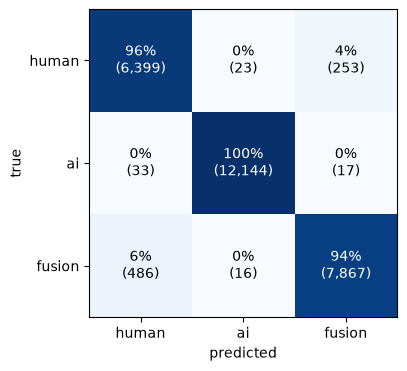

In [50]:
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_confusion(y, final_pred, ax)
plt.show()

Macro-F1 of the final stacker and the single models by text length (left, if token counts are saved) and by language and domain (right).

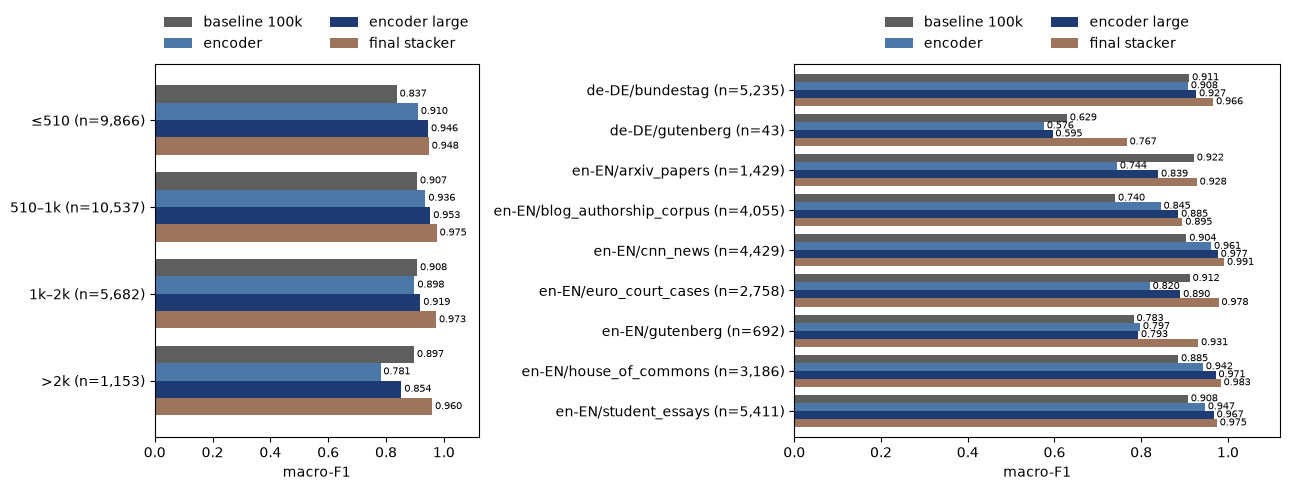

In [51]:
preds = {**single_preds, "final stacker": final_pred}
tokens = pickles("large_ids_{}") or pickles("enc_ids_{}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 3]})
if tokens is not None:
    val["band"] = length_band(tokens[0]["n_tokens"])
    plot_compare(compare_groups(val, preds, "band"), axes[0], MODEL_COLORS)
else:
    print("[warning] token counts not found: length plot skipped")
    axes[0].set_axis_off()
plot_compare(compare_groups(val, preds, ["lang", "domain"]), axes[1], MODEL_COLORS)
plt.tight_layout()
plt.show()

## Submission

The final stacker is fitted on all validation rows and predicts the test set (`final`); the large encoder alone is the fallback (`large`, if its results are there). Both files are always saved; only the ones listed in `SUBMIT` are uploaded to Kaggle (cached, so a rerun does not spend more daily submissions).

In [54]:
test_preds = {"final": fit_predict(X_val, y, X_test, kind=KIND, seed=SEED)}
if "L" in test_groups:
    test_preds["large"] = label_order[test_groups["L"].argmax(axis=1)]
else:
    print("[warning] large encoder results not found: fallback submission skipped")
messages = {"final": f"final stacker {CHOSEN} ({KIND}), val OOF macro-F1 {macro_f1(y, final_pred):.4f}",
            "large": f"large encoder alone, val macro-F1 {macro_f1(y, single_preds.get('encoder large', final_pred)):.4f}"}

for name in sorted(set(SUBMIT) - set(test_preds)):
    print(f"[warning] {name} is not available: not uploaded")
for name, pred in test_preds.items():
    path = write_submission(test["id"], pred, sample_submission, name)
    if name in SUBMIT:
        cached(f"{name}_upload", lambda: submit_to_kaggle(path, messages[name]), key={**type_key, "kind": KIND, "file": name},
               kind="json")
print(f"saved: {list(test_preds)} | uploaded (now or earlier): {[n for n in test_preds if n in SUBMIT] or 'none'}")
pd.DataFrame({name: pd.Series(pred).value_counts(normalize=True).reindex(LABEL_ORDER).mul(100).round(1)
              for name, pred in test_preds.items()}).T.rename_axis("share of test predictions, %")

100%|██████████| 285k/285k [00:00<00:00, 319kB/s]


[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/final_upload.json


100%|██████████| 285k/285k [00:00<00:00, 320kB/s]


[cache] saved /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/large_upload.json
saved: ['final', 'large'] | uploaded (now or earlier): ['final', 'large']


,human,ai,fusion
"share of test predictions, %",,,
final,25.9,51.4,22.7
large,24.6,51.6,23.8


## Conclusions

_To be written after the run._